In [8]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [9]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import re
import matplotlib.pyplot as plt

In [ ]:
def visualise_biosignal(data):
    """Visualise the biosignal data.
    
    Args:
        data (np.ndarray): Shape (n_samples, n_channels)
    """
    plt.figure(figsize=(12, 4))
    print(f"Data shape: {data.shape}")
    offsets = np.arange(data.shape[1]) * 100  # Offset each channel for better visualization
    print(f"Offsets: {offsets}")
    plot_data = data + offsets[np.newaxis, :]  # Add offsets to each channel
    plt.plot(plot_data)
    plt.title("Biosignal Visualization")
    plt.xlabel("Time (samples)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.show()

Keys in user group: ['ses-01']
Keys in session group: ['run-01', 'run-02', 'run-03', 'run-04', 'run-05', 'run-06', 'run-07', 'run-08', 'run-09', 'run-10']
Keys in run group: ['eeg', 'emg', 'event_id', 'pos']
EEG shape: (204912, 8)
Data shape: (3000, 8)
Offsets: [  0 100 200 300 400 500 600 700]


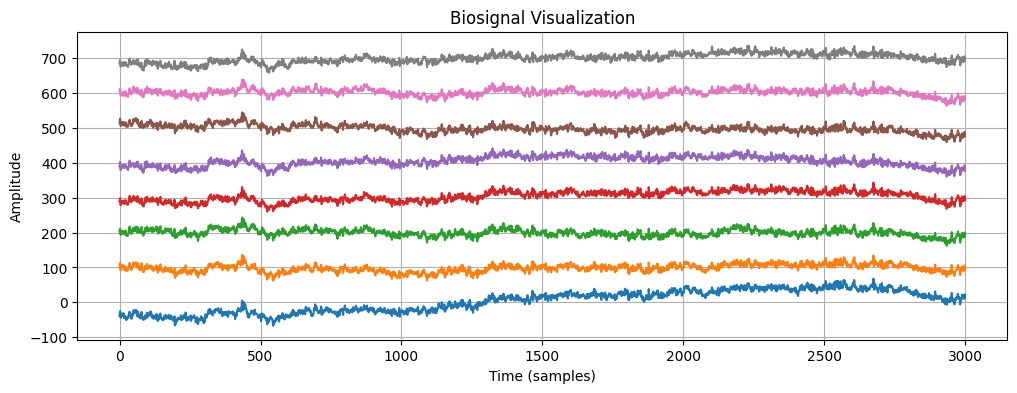

EMG shape: (204912, 8)
Data shape: (3000, 8)
Offsets: [  0 100 200 300 400 500 600 700]


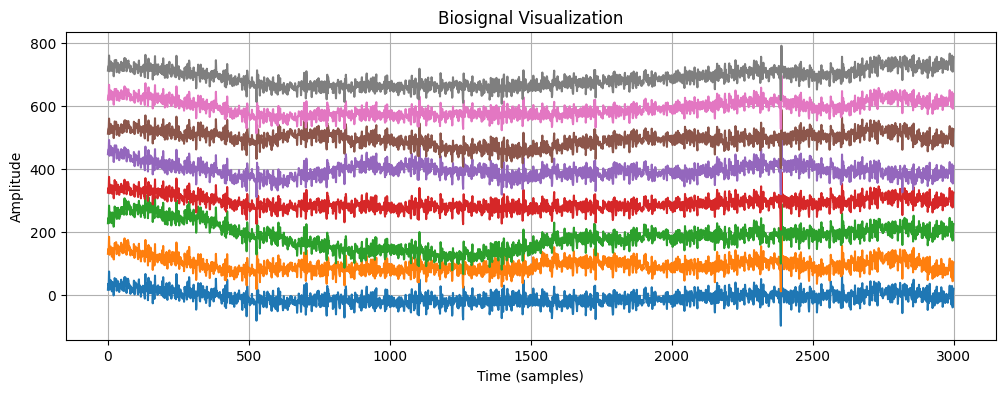

In [25]:
with h5py.File("data/eeg-emg-wristmotion/eeg-emg-wristmotion.hdf5", 'r') as f:
    root = f['eeg-emg-wristmotion']
    
    user_group = root['sub-11']
    print("Keys in user group:", list(user_group.keys()))
    session_group = user_group['ses-01']
    print("Keys in session group:", list(session_group.keys()))
    run_group = session_group['run-01']
    print("Keys in run group:", list(run_group.keys()))
    eeg = run_group['eeg']
    print("EEG shape:", eeg.shape)
    visualise_biosignal(eeg[2000:5000, :])

    emg = run_group['emg']
    print("EMG shape:", emg.shape)
    visualise_biosignal(emg[2000:5000, :])

In [8]:
with h5py.File("data/eeg-emg-wristmotion/eeg-emg-wristmotion.hdf5", 'r') as f:
    root = f['eeg-emg-wristmotion']
    for user_key in root:
        print(user_key)
        user_group = root[user_key]
        for session_key in user_group:
            print(f"  {session_key}")
            session_group = user_group[session_key]
            
            for run_key in session_group:
                print(f"    {run_key}")
                run_group = session_group[run_key]
                print(f'      {list(run_group.attrs.items())}')
                print(f'      {list(run_group.keys())}')
                if 'eeg' in run_group:
                    eeg_ds = run_group['eeg']
                    print(f'      {eeg_ds.shape}')
                    print(f'      {list(eeg_ds.attrs.items())}')

sub-01
  ses-01
    run-01
      [('intra_session_split', 'n/a'), ('manufacturer', 'n/a'), ('origin_path', 'data/eeg-emg-wristmotion/sub-01/eeg/sub-01_task-WristPointingTask_run-01_eeg.edf'), ('run_id', 'run-01'), ('sample_rate', np.int64(100)), ('sensor_type', 'n/a'), ('task_name', 'WristPointingTask')]
      ['eeg', 'emg', 'event_id', 'pos']
      (204864, 8)
      [('n_channels', np.int64(8)), ('n_samples', np.int64(204864)), ('origin_path', 'data/eeg-emg-wristmotion/sub-01/eeg/sub-01_task-WristPointingTask_run-01_eeg.edf'), ('recording_duration', np.float64(400.125)), ('sample_rate', np.int64(512)), ('sensor_type', 'g.USBamp')]
    run-02
      [('intra_session_split', 'n/a'), ('manufacturer', 'n/a'), ('origin_path', 'data/eeg-emg-wristmotion/sub-01/eeg/sub-01_task-WristPointingTask_run-03_eeg.edf'), ('run_id', 'run-02'), ('sample_rate', np.int64(100)), ('sensor_type', 'n/a'), ('task_name', 'WristPointingTask')]
      ['eeg', 'emg', 'event_id', 'pos']
      (204856, 8)
      [('n_c

In [9]:
def extract_dataset_metadata(hdf5_path, root_key, data_keys=['emg']):
    """
    Crawls a unified biosignal HDF5 file and flattens metadata into a DataFrame.
    """
    records = []
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            raise KeyError(f"Root key '{root_key}' not found in {hdf5_path}")
        
        root = f[root_key]
        for subj_id in tqdm(root.keys(), desc=f"Scanning {root_key}"):
            subj_group = root[subj_id]
            subj_meta = dict(subj_group.attrs)
            
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                sess_meta = dict(sess_group.attrs)

                for run_key in sess_group.keys():
                    if not isinstance(sess_group[run_key], h5py.Group):
                        continue
                    
                    run_group = sess_group[run_key]
                    run_meta = dict(run_group.attrs)

                    record = {
                        **subj_meta,
                        **sess_meta,
                        **run_meta,
                        'subj_key': subj_id,
                        'sess_key': sess_id,
                        'run_key': run_key
                    }

                    for data_key in data_keys:
                        if data_key not in run_group:
                            print(f"Warning: '{data_key}' not found in {subj_id}/{sess_id}/{run_key}")
                            continue
                        data = run_group[data_key]
                        if not isinstance(data, h5py.Dataset):
                            print(f"Warning: '{data_key}' in {subj_id}/{sess_id}/{run_key} is not a dataset")
                            continue
                            
                        t, c = data.shape
                        fs = data.attrs.get('sample_rate', None)
                        if fs is None:
                            print(f"Warning: 'sample_rate' attribute not found for '{data_key}' in {subj_id}/{sess_id}/{run_key}")
                            continue

                        record.update({
                            f'{data_key}_num_samples': t,
                            f'{data_key}_num_channels': c,
                            f'{data_key}_duration_sec': t / fs,
                            f'{data_key}_mean': np.mean(data),
                            f'{data_key}_std': np.std(data)
                        })

                    records.append(record)
                
    df = pd.DataFrame(records)
    # Ensure participant_id is a sortable type (int if possible, else string)
    # Ensure participant_num is a sortable type (int if possible)
    # Participarn ID is often a string like "subject_01", so we can extract the numeric part for sorting
    try:
        regex = re.compile(r'\d+')
        df['participant_number'] = df['participant_id'].apply(lambda x: int(regex.search(str(x)).group()) if regex.search(str(x)) else x)
        df.sort_values('participant_number', inplace=True)
    except:
        pass
        
    return df

In [10]:
df = extract_dataset_metadata("data/eeg-emg-wristmotion/eeg-emg-wristmotion.hdf5", root_key="eeg-emg-wristmotion", data_keys=['eeg'])

Scanning eeg-emg-wristmotion:  73%|███████▎  | 33/45 [00:08<00:03,  3.84it/s]

Scanning eeg-emg-wristmotion: 100%|██████████| 45/45 [00:11<00:00,  4.06it/s]


In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

class BiosignalAuditor:
    def __init__(self, df, dataset_name="Dataset", label_key='gesture_id', data_key='{self.data_key}'):
        self.df = df
        self.name = dataset_name.upper()
        # Filter out unlabelled for core distribution plots
        self.df_clean = df[df[label_key] != -1].copy()
        self.label_key = label_key
        self.data_key = data_key
        
        plt.style.use('seaborn-v0_8-muted')
        sns.set_context("talk")

    def run_full_audit(self):
        """Executes all visualization and statistical checks."""
        self.plot_overview()
        self.plot_length_leakage_check()
        self.print_summary()

    def plot_overview(self):
        fig, axes = plt.subplots(5, 2, figsize=(40, 50))
        plt.subplots_adjust(hspace=0.4)
            
        # 1. Class Distribution (Gesture ID)
        # This checks for "Label Imbalance"
        sns.countplot(data=self.df, x=self.label_key, hue='intra_session_split', ax=axes[0,0])
        axes[0,0].set_title("Gesture Class Distribution (Intra-Session Split)")
        axes[0,0].tick_params(axis='x', rotation=45)


        sns.countplot(data=self.df, x=self.label_key, hue='inter_subject_split', ax=axes[0,1])
        axes[0,1].set_title("Gesture Class Distribution (Inter-Subject Split)")
        axes[0,1].tick_params(axis='x', rotation=45)


        # 2. Duration Distribution
        sns.histplot(data=self.df_clean, x=f'{self.data_key}_duration_sec', hue='intra_session_split', multiple="stack", ax=axes[1,0])
        axes[1,0].set_title("Distribution of Trial Durations - Intra-session split (Seconds)")

        sns.histplot(data=self.df_clean, x=f'{self.data_key}_duration_sec', hue='inter_subject_split', multiple="stack", ax=axes[1,1])
        axes[1,1].set_title("Distribution of Trial Durations - Inter-subject split (Seconds)")

        # 3. Leakage Heatmap (Subject-to-Split Mapping)
        leak_table = pd.crosstab(self.df['participant_id'], self.df['intra_session_split'])
        sns.heatmap(leak_table, annot=True, cbar=False, cmap='Blues', ax=axes[2,0])
        axes[2,0].set_title("Session Leakage Check")

        leak_table = pd.crosstab(self.df['participant_id'], self.df['inter_subject_split'])
        sns.heatmap(leak_table, annot=True, cbar=False, cmap='Blues', ax=axes[2,1])
        axes[2,1].set_title("Subject Leakage Check")


        # 4. Signal Quality (Mean vs Std per Session)
        sns.scatterplot(data=self.df_clean, x=f'{self.data_key}_mean', y=f'{self.data_key}_std', hue='intra_session_split', alpha=0.5, ax=axes[3,0])
        axes[3,0].set_title("Signal Energy (Mean vs Std) - Quality Check")
        # axes[3,0].get_legend().remove()


        # 5. Signal Quality (Mean vs Std per Subject)
        sns.scatterplot(data=self.df_clean, x=f'{self.data_key}_mean', y=f'{self.data_key}_std', hue='participant_id', alpha=0.5, ax=axes[3,1])
        axes[3,1].set_title("Signal Energy (Mean vs Std) - Quality Check")
        # axes[3,1].get_legend().remove()


        # 6. Sex Distribution pie chart
        axes[4,0].pie(self.df_clean['sex'].value_counts(), labels=self.df_clean['sex'].unique(), autopct='%1.1f%%', colors=sns.color_palette('Set2')) 
        axes[4,0].set_title("Gender Distribution")

        # 7. Handedness Distribution
        axes[4,1].pie(self.df_clean['handedness'].value_counts(), labels=self.df_clean['handedness'].unique(), autopct='%1.1f%%', colors=sns.color_palette('Set2'))
        axes[4,1].set_title("Handedness Distribution")


        plt.show()

    def plot_length_leakage_check(self):
        """Checks if gesture ID is perfectly predictable by signal duration."""
        plt.figure(figsize=(16, 6))
        sns.boxplot(data=self.df_clean.sort_values(self.label_key), x=self.label_key, y=f'{self.data_key}_duration_sec', palette='husl')
        plt.axhline(self.df_clean[f'{self.data_key}_duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
        plt.title(f"{self.name}: Signal Length Leakage Audit")
        plt.xticks(rotation=90 if self.df_clean[self.label_key].nunique() > 10 else 0)
        plt.legend()
        plt.show()

    def print_summary(self):
        print(f"\n{'='*40}\n{self.name} AUDIT REPORT\n{'='*40}")
        print(f"Total Subjects: {self.df['participant_id'].nunique()}")
        print(f"Total Trials:   {len(self.df)}")
        print(f"Total {self.data_key} Time: {self.df[f'{self.data_key}_duration_sec'].sum() / 3600:.2f} hours")
        
        for col in ['intra_session_split', 'intra_session_split', 'subject_split', 'inter_subject_split']:
            if col in self.df.columns:
                print(f"\nSplit Distribution ({col}):")
                print(self.df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

        # Check for Inter-Subject Leakage
        subj_split_col = next((c for c in ['subject_split', 'inter_subject_split'] if c in self.df.columns), None)
        if subj_split_col:
            leak_check = self.df.groupby('participant_id')[subj_split_col].nunique()
            leaked = leak_check[leak_check > 1].index.tolist()
            if leaked:
                print(f"\n⚠️ WARNING: {len(leaked)} subjects found in multiple splits: {leaked[:5]}...")
            else:
                print("\n✅ Clean: No subject leakage detected across splits.")

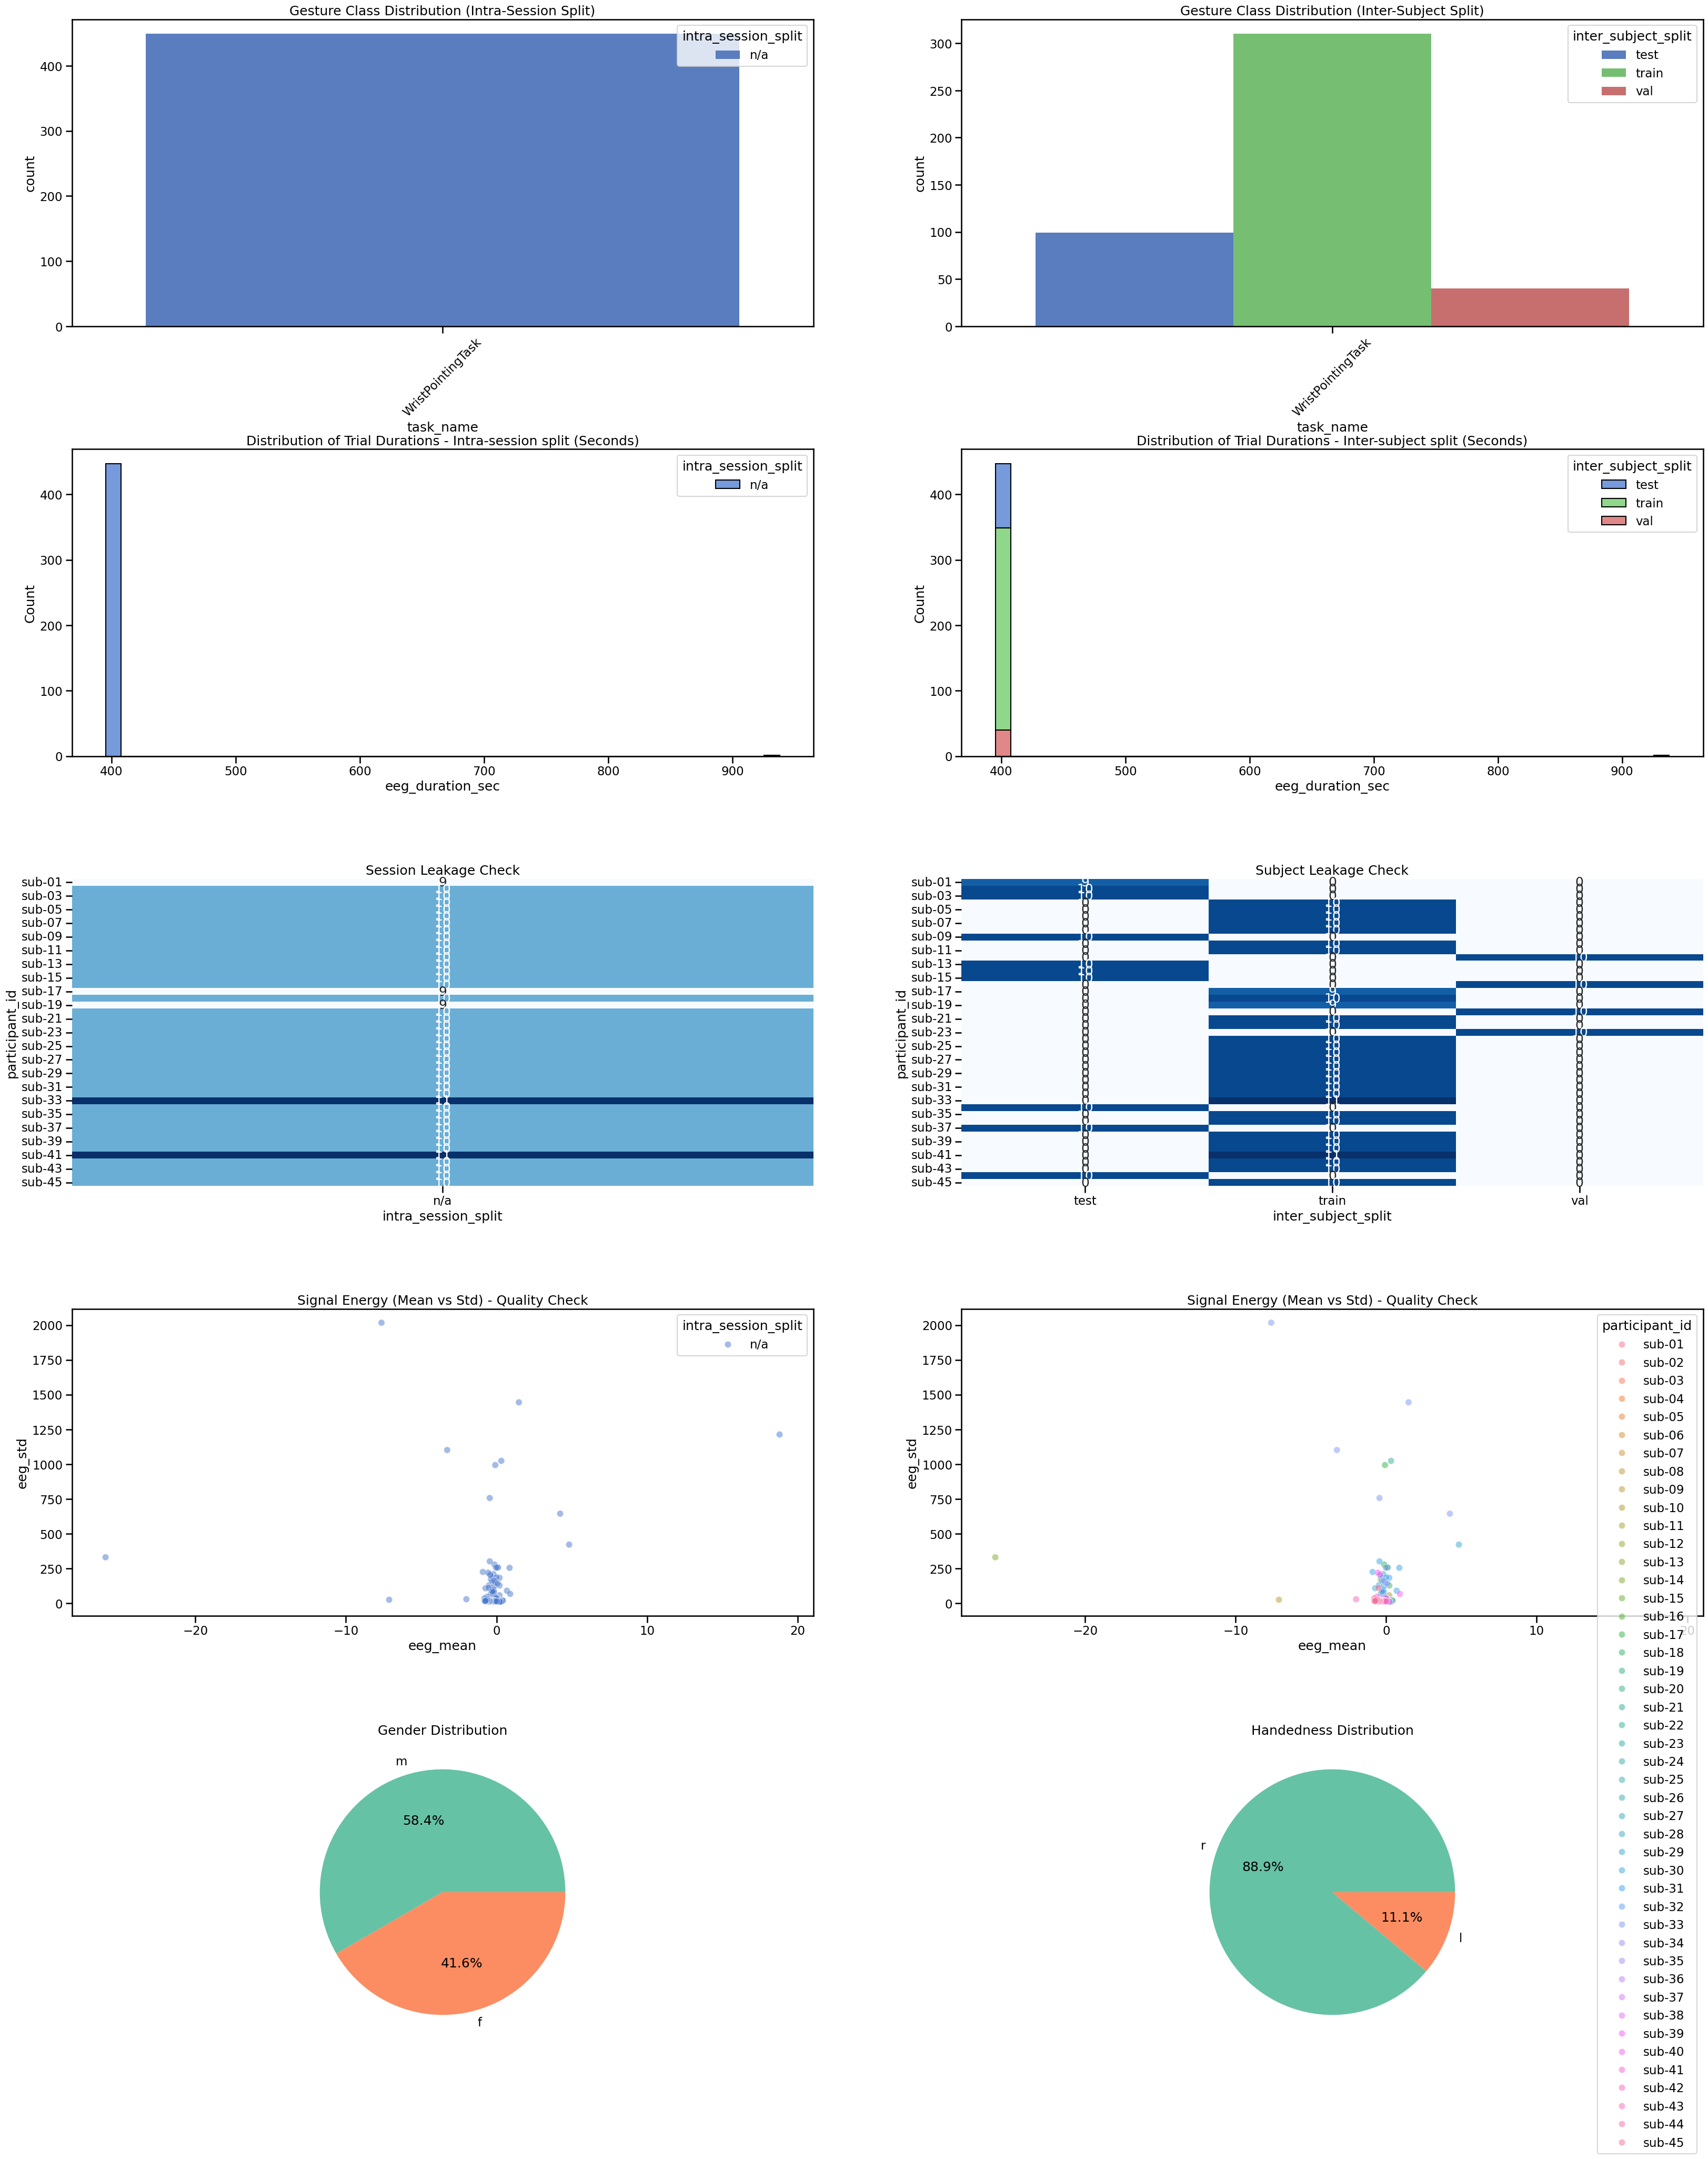

/tmp/ipykernel_1017589/3150362774.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=self.df_clean.sort_values(self.label_key), x=self.label_key, y=f'{self.data_key}_duration_sec', palette='husl')


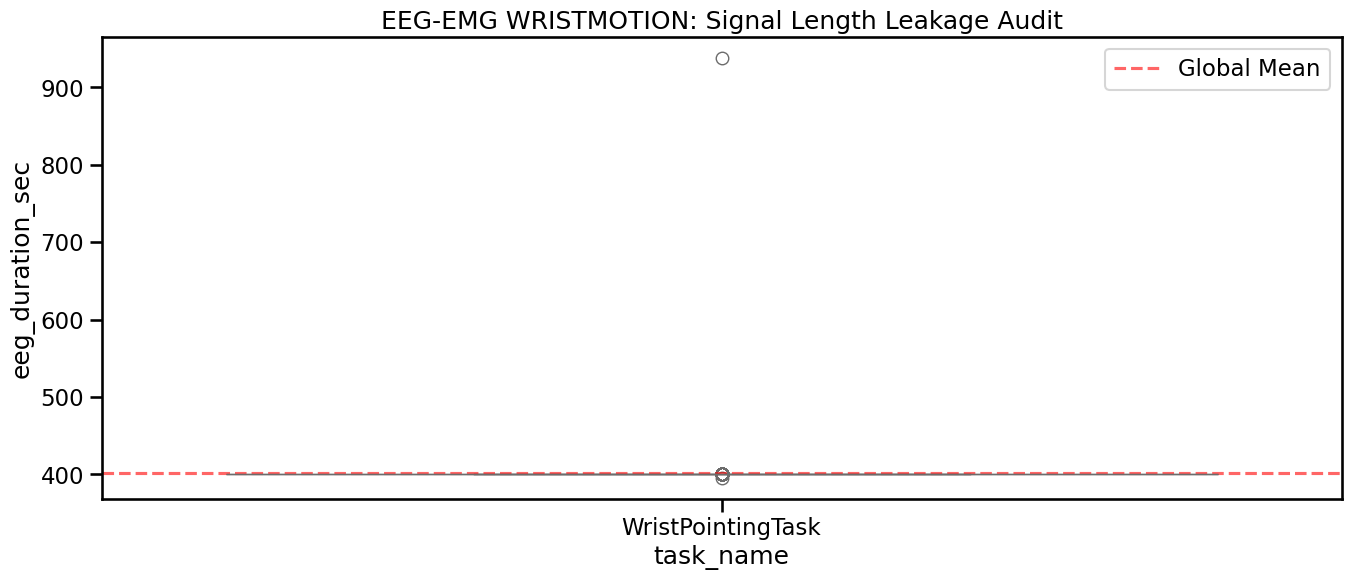


EEG-EMG WRISTMOTION AUDIT REPORT
Total Subjects: 45
Total Trials:   449
Total eeg Time: 49.95 hours

Split Distribution (intra_session_split):
intra_session_split
n/a    100.0%
Name: proportion, dtype: object

Split Distribution (intra_session_split):
intra_session_split
n/a    100.0%
Name: proportion, dtype: object

Split Distribution (inter_subject_split):
inter_subject_split
train    69.04%
test     22.05%
val       8.91%
Name: proportion, dtype: object

✅ Clean: No subject leakage detected across splits.


In [12]:
auditor = BiosignalAuditor(df, "EEG-EMG WristMotion", label_key='task_name', data_key='eeg')
auditor.run_full_audit()